---
title: "Week 8A: OpenStreetMap, Routing, and Accessibility"
format:
  html:
    toc: true
    toc-depth: 2
    number-sections: true
    code-fold: false
    embed-resources: true
    theme: cosmo
execute:
  enabled: false
---

## Overview

How do street networks shape the routes we take and the amenities we can reach?

This lab uses **OSMnx** to work with OpenStreetMap (OSM) street networks and **Pandana** to measure access to amenities in Center City, Philadelphia.

By the end, you will be able to:

- Read place boundaries, tagged features, and street networks from OSM.
- Explain the difference between driving and walking networks.
- Compare a shortest-distance route with a minimum estimated travel-time route.
- Map the network distance to the nearest and third-nearest amenity.

**Suggested class flow:** OSM and data (10 minutes), graphs and routing (20 minutes), accessibility (20 minutes), discussion (10 minutes). Week 8B then examines how to build a graph from sidewalk lines yourself.

## Setup and classroom data

Use **OSMnx 2.x**, GeoPandas, NetworkX, Pandana, NumPy, pandas, and Matplotlib. A conda environment from conda-forge is a convenient way to install the geospatial dependencies:

```bash
conda create -n street-networks -c conda-forge python=3.11 "osmnx>=2,<3" geopandas networkx pandana numpy pandas matplotlib jupyterlab
conda activate street-networks
jupyter lab
```

Open this notebook from the lab folder or the course `public` folder. Select that environment's kernel and run cells in order.

**Reproducible default:** files in `data/week8a/` were prepared from this lab's existing OSM response cache dated **October 16, 2025**. The core lesson needs no live OSM download. These historical snapshots are not a current inventory. Keep the data folder with the notebook.

Set `REFRESH_FROM_OSM = True` to run the demonstrated OSMnx queries instead. That optional mode requires internet access, may take several minutes, and can return different results. It does not replace the supplied snapshot files.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd
import pandana as pdna
from IPython.display import display

if int(ox.__version__.split(".")[0]) < 2:
    raise ImportError("This lesson uses OSMnx 2.x. Select the street-networks environment.")

plt.rcParams.update({"figure.figsize": (9, 6), "font.size": 11})
print(f"OSMnx {ox.__version__} | GeoPandas {gpd.__version__} | Pandana {pdna.__version__}")

lab_dir = Path.cwd()
if not (lab_dir / "data/week8a").exists():
    lab_dir = lab_dir / "labs/week-8-network-analysis"
data_dir = lab_dir / "data/week8a"
if not data_dir.exists():
    raise FileNotFoundError("The supplied data/week8a folder must accompany this notebook.")

REFRESH_FROM_OSM = False
ox.settings.use_cache = True
ox.settings.cache_folder = lab_dir / "cache"
ox.settings.log_console = False

OSMnx 2.0.6 | GeoPandas 1.1.1 | Pandana 0.7


## OpenStreetMap: boundaries and features

OSM is a collaborative geographic database. Features are described with **key–value tags**: `amenity=restaurant`, `highway=bus_stop`, or `landuse=retail`, for example. Features may be points, lines, or polygons; an amenity is not necessarily a point.

OSMnx returns boundaries and features as GeoDataFrames, and networks as NetworkX graphs. Data completeness varies by place and feature type. Attribute all maps and derived data to [OpenStreetMap contributors](https://www.openstreetmap.org/copyright).

### Get a place boundary

`geocode_to_gdf()` resolves a place name to a boundary. Check the returned name and geometry before proceeding. Geographic coordinates are longitude/latitude in degrees; use an appropriate projected CRS for local planar measurements.

Boundary CRS: EPSG:4326


,display_name,geometry
0,"Philadelphia, Philadelphia County, Pennsylvani...","POLYGON ((-75.28027 39.97496, -75.28023 39.974..."


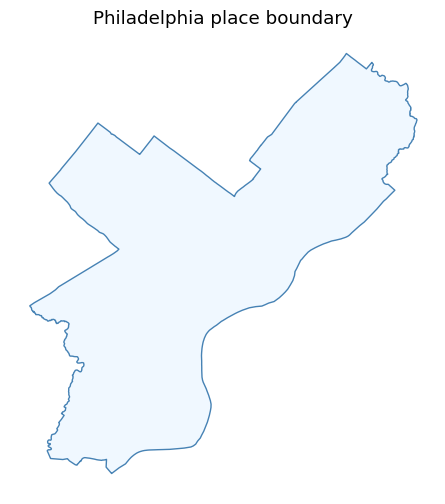

In [2]:
if REFRESH_FROM_OSM:
    philly = ox.geocode_to_gdf("Philadelphia, PA")
else:
    philly = gpd.read_file(data_dir / "classroom.gpkg", layer="philadelphia")

print("Boundary CRS:", philly.crs)
display(philly[["display_name", "geometry"]].head())
philly_m = ox.projection.project_gdf(philly)
metric_crs = philly_m.crs
ax = philly_m.plot(facecolor="aliceblue", edgecolor="steelblue")
ax.set_title("Philadelphia place boundary")
ax.set_axis_off()
plt.show()

### Query features by tags

The live query below requests all amenity types with `tags={"amenity": True}`. More focused examples are:

```python
# Examples to try in a separate cell when online:
# ox.features_from_place("Philadelphia, PA", tags={"amenity": "school"})
# ox.features_from_place("Philadelphia, PA", tags={"amenity": ["cafe", "restaurant"]})
```

The classroom amenity snapshot is restricted to the walking network's bounding box. We apply the same spatial filter to live results after loading the network. OSM feature IDs identify mapped objects, not necessarily distinct real-world businesses or facilities.

In [3]:
if REFRESH_FROM_OSM:
    amenities = ox.features_from_place("Philadelphia, PA", tags={"amenity": True})
else:
    amenities = gpd.read_file(data_dir / "classroom.gpkg", layer="amenities")

print("Amenity geometries:")
print(amenities.geom_type.value_counts())
display(amenities[["amenity", "name", "geometry"]].head())

Amenity geometries:
Point           1952
Polygon         1101
LineString         2
MultiPolygon       1
Name: count, dtype: int64


,amenity,name,geometry
0,parking_entrance,None,POINT (-75.15662 39.9504)
1,car_sharing,None,POINT (-75.16694 39.96394)
2,car_sharing,None,POINT (-75.17041 39.96398)
3,restaurant,Sam's Morning Glory,POINT (-75.15893 39.94086)
4,cafe,Chapter House,POINT (-75.15736 39.94192)


## Street networks with OSMnx

### Download or load driving and walking graphs

`graph_from_address()` first geocodes an address, then extracts a network within a bounding box extending approximately `dist` meters in each direction. This is **not a network-distance service area**.

- `drive` models streets available for driving, including one-way direction.
- `walk` includes pedestrian paths and treats travel as bidirectional.

Both are `MultiDiGraph` objects: nodes represent network locations, directed edges represent travel connections, and parallel edges can connect the same nodes. Simplification retains street shape while removing intermediate geometry-only nodes.

Other spatial query choices include `graph_from_place()`, `graph_from_point()`, and `graph_from_polygon()`. A polygon passed to OSMnx must be in EPSG:4326.

In [4]:
if REFRESH_FROM_OSM:
    G_drive = ox.graph_from_address(
        "Center City, Philadelphia, PA", dist=2000, network_type="drive"
    )
    G_walk = ox.graph_from_address(
        "Center City, Philadelphia, PA", dist=2000, network_type="walk"
    )
else:
    G_drive = ox.load_graphml(data_dir / "drive.graphml.gz")
    G_walk = ox.load_graphml(data_dir / "walk.graphml.gz")

print("Graph type:", type(G_drive).__name__)
for label, graph in [("Driving", G_drive), ("Walking", G_walk)]:
    print(f"{label}: {len(graph):,} nodes; {graph.number_of_edges():,} directed edges")

G_drive_m = ox.projection.project_graph(G_drive, to_crs=metric_crs)
G_walk_m = ox.projection.project_graph(G_walk, to_crs=metric_crs)

Graph type: MultiDiGraph
Driving: 2,269 nodes; 4,331 directed edges
Walking: 10,655 nodes; 31,854 directed edges


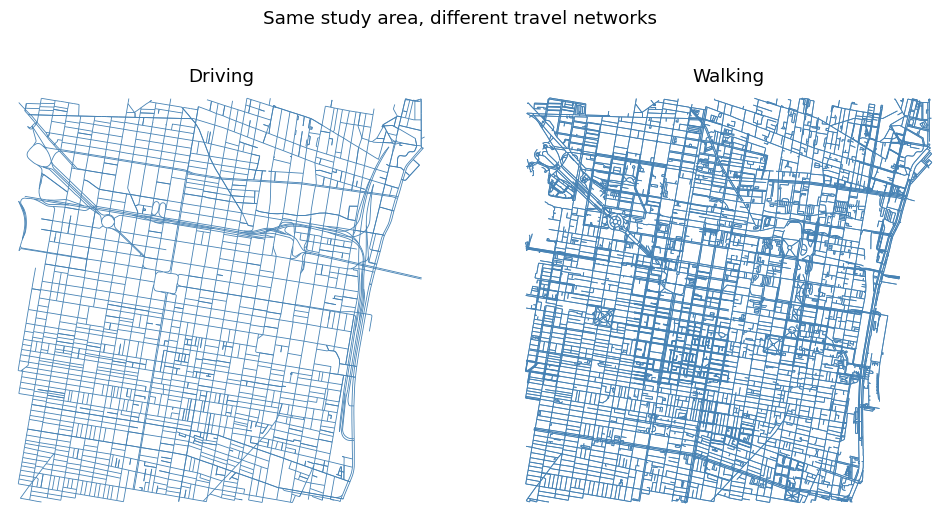

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, graph, label in zip(axes, [G_drive_m, G_walk_m], ["Driving", "Walking"]):
    ox.plot_graph(graph, ax=ax, node_size=0, edge_color="steelblue",
                  edge_linewidth=0.6, bgcolor="white", show=False, close=False)
    ax.set_title(label)
fig.suptitle("Same study area, different travel networks")
plt.show()

### Convert graphs to GeoDataFrames

`graph_to_gdfs()` exposes node and edge attributes for mapping and analysis. Edge rows use a three-part index `(u, v, key)` to identify the origin node, destination node, and parallel edge.

The OSMnx `length` attribute is already in **meters**, even on the unprojected graph. Do not calculate `.length` on longitude/latitude geometries and interpret it as meters.

highway      length  \
u         v         key                            
109727353 109727357 0    residential  136.797865   
          110024116 0    residential   48.243085   
109727357 109924757 0    residential   40.212876   
110024116 110024127 0       tertiary  136.835432   
          110145261 0    residential   45.969102   

                                                                  geometry  
u         v         key                                                     
109727353 109727357 0    LINESTRING (485223.174 4420538.576, 485198.571...  
          110024116 0    LINESTRING (485223.174 4420538.576, 485270.834...  
109727357 109924757 0    LINESTRING (485198.571 4420404.249, 485158.819...  
110024116 110024127 0    LINESTRING (485270.834 4420530.504, 485245.899...  
          110145261 0    LINESTRING (485270.834 4420530.504, 485316.249...

Amenity objects in the study extent: 3,056


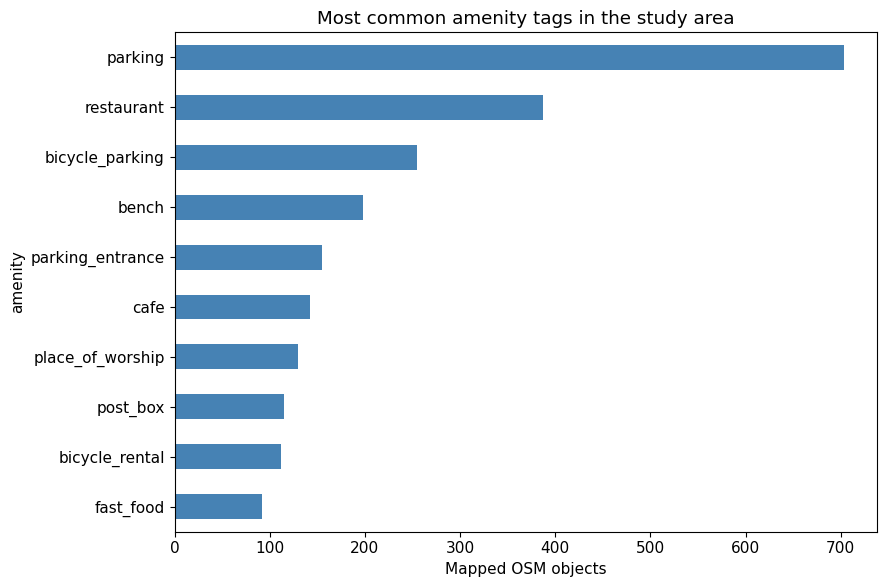

In [6]:
drive_nodes, drive_edges = ox.convert.graph_to_gdfs(G_drive_m)
walk_nodes, walk_edges = ox.convert.graph_to_gdfs(G_walk_m)
display(drive_edges[["highway", "length", "geometry"]].head())

# Apply the same geographic study extent to historical and refreshed amenities.
walk_nodes_ll = walk_nodes.to_crs(4326)
xmin, ymin, xmax, ymax = walk_nodes_ll.total_bounds
amenities = amenities.to_crs(4326).cx[xmin:xmax, ymin:ymax].copy()
print(f"Amenity objects in the study extent: {len(amenities):,}")
amenities["amenity"].value_counts().head(10).sort_values().plot.barh(color="steelblue")
plt.xlabel("Mapped OSM objects")
plt.title("Most common amenity tags in the study area")
plt.tight_layout()
plt.show()

### Summarize the graph

Directed edge counts are not counts of unique physical streets: a two-way street usually contributes an edge in each direction. OSMnx basic statistics account for this distinction for street-based measures.

In [7]:
stats = ox.stats.basic_stats(G_drive)
selected_stats = {
    "Nodes": stats["n"],
    "Directed edges": stats["m"],
    "Intersections": stats["intersection_count"],
    "Total physical street length (km)": stats["street_length_total"] / 1000,
    "Mean physical street segment length (m)": stats["street_length_avg"],
}
display(pd.Series(selected_stats, name="Driving network").to_frame().round(2))

,Driving network
Nodes,2269.00
Directed edges,4331.00
Intersections,2189.00
Total physical street length (km),328.25
Mean physical street segment length (m),87.49


### Inspect street orientations

A polar histogram summarizes street bearings. Use an **unprojected, undirected** graph so both directions of a physical street are represented consistently. Bearings summarize endpoint-to-endpoint direction, not every bend in a street.

**Discuss:** what pattern would you expect from a regular street grid?

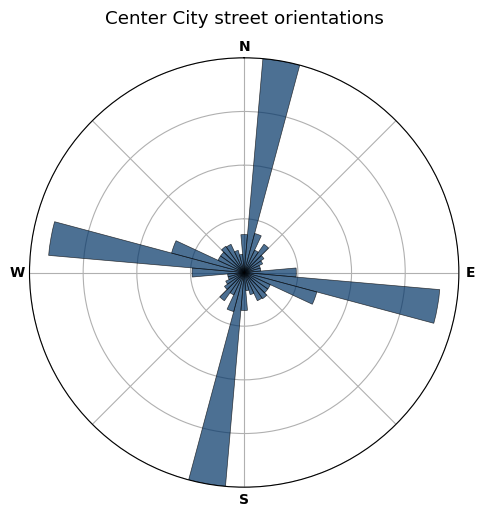

In [8]:
G_bearings = ox.bearing.add_edge_bearings(G_drive)
G_undirected = ox.convert.to_undirected(G_bearings)
fig, ax = ox.plot.plot_orientation(G_undirected, figsize=(5, 5))
ax.set_title("Center City street orientations", pad=25)
plt.show()

## Routing: distance versus estimated travel time

### Snap two locations to the driving network

Use approximate demonstration locations near **City Hall** and the **Liberty Bell**. These coordinates are fixed so the lesson does not depend on changing OSM place names or exact feature matches. They are not verified curbside access points.

Create points as `(longitude, latitude)`, project them to the graph CRS, and pass `X` and `Y` to `nearest_nodes()`. Inspect the snapping distances. Routing between the snapped nodes excludes the connections from the input locations to the network.

In [9]:
locations = gpd.GeoDataFrame(
    {"name": ["City Hall", "Liberty Bell"]},
    geometry=gpd.points_from_xy([-75.1636, -75.1503], [39.9526, 39.9496]),
    crs=4326,
).to_crs(metric_crs)
node_ids, snap_distances = ox.distance.nearest_nodes(
    G_drive_m, X=locations.geometry.x, Y=locations.geometry.y, return_dist=True
)
locations["node_id"] = node_ids
locations["snap_distance_m"] = snap_distances
origin, destination = node_ids
if origin == destination or not nx.has_path(G_drive_m, origin, destination):
    raise ValueError("Choose two distinct locations connected by a directed route.")
display(locations[["name", "node_id", "snap_distance_m"]].round(1))

,name,node_id,snap_distance_m
0,City Hall,110402209,87.2
1,Liberty Bell,3408446156,29.5


### Add an estimated travel-time cost

`add_edge_speeds()` uses available `maxspeed` tags and imputes missing speeds by road type; `add_edge_travel_times()` converts edge length and speed to seconds. A 30 km/h fallback is an **explicit classroom assumption** for otherwise unresolved values.

These are free-flow estimates, not live traffic or observed trip times. Traffic lights, congestion, parking, and turn restrictions are not modeled here.

**Predict:** must the shortest-distance route also have the smallest estimated travel time?

In [10]:
G_cost = ox.routing.add_edge_speeds(G_drive_m.copy(), fallback=30)
G_cost = ox.routing.add_edge_travel_times(G_cost)

route_short = ox.routing.shortest_path(G_cost, origin, destination, weight="length")
route_fast = ox.routing.shortest_path(G_cost, origin, destination, weight="travel_time")
if route_short is None or route_fast is None:
    raise ValueError("No directed route exists between the selected nodes.")

# Select parallel edges using the SAME cost used to find each route.
short_edges = ox.routing.route_to_gdf(G_cost, route_short, weight="length")
fast_edges = ox.routing.route_to_gdf(G_cost, route_fast, weight="travel_time")

# Measure distance AND time on each selected set of edges.
comparison = pd.DataFrame([
    {"Route": label, "Distance (km)": edges["length"].sum() / 1000,
     "Estimated time (min)": edges["travel_time"].sum() / 60}
    for label, edges in [("Shortest distance", short_edges), ("Minimum estimated time", fast_edges)]
]).set_index("Route")
display(comparison.round(2))
assert short_edges["length"].sum() <= fast_edges["length"].sum() + 1e-6
assert fast_edges["travel_time"].sum() <= short_edges["travel_time"].sum() + 1e-6

,Distance (km),Estimated time (min)
Route,,
Shortest distance,1.72,2.53
Minimum estimated time,1.73,2.52


### Map and compare the routes

Plot the actual edge geometries selected above. A node sequence alone does not specify which parallel edge was used. Keeping the selected edge GeoDataFrames also ensures that the map and comparison table describe the same routes.

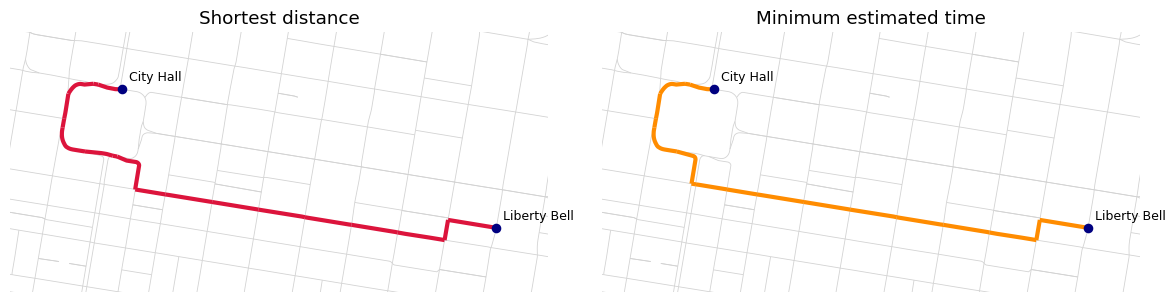

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
route_bounds = np.vstack([short_edges.total_bounds, fast_edges.total_bounds])
x0, y0 = route_bounds[:, :2].min(axis=0) - 150
x1, y1 = route_bounds[:, 2:].max(axis=0) + 150
for ax, edges, label, color in zip(
    axes, [short_edges, fast_edges],
    ["Shortest distance", "Minimum estimated time"], ["crimson", "darkorange"]
):
    drive_edges.plot(ax=ax, color="lightgray", linewidth=0.6)
    edges.plot(ax=ax, color=color, linewidth=3)
    snapped = drive_nodes.loc[node_ids]
    snapped.plot(ax=ax, color="navy", markersize=35, zorder=4)
    for name, point in zip(locations.name, snapped.geometry):
        ax.annotate(name, (point.x, point.y), xytext=(5, 6),
                    textcoords="offset points", fontsize=9)
    ax.set(xlim=(x0, x1), ylim=(y0, y1), title=label)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

### Optional interactive map

The static figures above are embedded in the HTML page. To explore the route interactively in Jupyter, install `folium` and `mapclassify`, then enable the cell below. The basemap and web-map assets require internet access.

In [12]:
SHOW_INTERACTIVE_MAP = False
if SHOW_INTERACTIVE_MAP:
    route_map = short_edges.to_crs(4326).explore(
        tiles="CartoDB positron", color="crimson",
        tooltip=["length", "travel_time"],
    )
    display(route_map)
else:
    print("Optional interactive map disabled; the static route maps are shown above.")

Optional interactive map disabled; the static route maps are shown above.


## Amenity accessibility with Pandana

A route answers “how do I get from A to B?” Accessibility asks “how far is each network location from an amenity?” Pandana efficiently repeats network-distance queries for many nodes.

### Build a Pandana network from the walking graph

Reuse the OSMnx walking graph instead of downloading another network with a separate loader. Its edge `length` is the distance cost in meters.

The walking graph already contains both travel directions. Use `twoway=False` so Pandana preserves those directed records without adding reverse duplicates. For parallel edges with the same `(u, v)`, retain the shortest edge for distance-only analysis.

In [13]:
walk_links = walk_edges.reset_index()[["u", "v", "length"]]
walk_links = walk_links.sort_values("length").drop_duplicates(["u", "v"])
walk_links = walk_links.loc[walk_links.u != walk_links.v].reset_index(drop=True)

net = pdna.Network(
    walk_nodes.geometry.x, walk_nodes.geometry.y,
    walk_links["u"], walk_links["v"], walk_links[["length"]],
    twoway=False,
)
MAX_DISTANCE_M = 2000
NUM_POIS = 3
net.precompute(MAX_DISTANCE_M)
print(f"Pandana network: {len(net.nodes_df):,} nodes")

Generating contraction hierarchies with 1 threads.
Setting CH node vector of size 10655
Setting CH edge vector of size 31500
Range graph removed 31500 edges of 63000
. 10% . 20% 

Pandana network: 10,655 nodes. 30% . 40% . 50% . 60% . 70% . 80% . 90% . 100%



### Represent amenities as points and register categories

For polygons, use an interior representative point after projecting to meters. This is a practical demonstration choice, not a verified entrance. Amenities are snapped to nearby network nodes; off-network access distance is not included in Pandana's path distance.

Retain amenities within 100 meters of a network node and report the exclusions. This threshold is an assumption to inspect, not a universal rule. Separate OSM objects can describe the same facility, so “third nearest” means the third mapped object unless you deduplicate facilities.

In [14]:
AMENITIES = ["restaurant", "school"]
valid = amenities.geometry.notna() & ~amenities.geometry.is_empty & amenities.geometry.is_valid
print(f"Excluded invalid or missing amenity geometries: {(~valid).sum():,}")
poi_points = amenities.loc[valid & amenities.amenity.isin(AMENITIES)].copy().to_crs(metric_crs)
poi_points.geometry = poi_points.geometry.representative_point()
_, poi_snap_m = ox.distance.nearest_nodes(
    G_walk_m, X=poi_points.geometry.x, Y=poi_points.geometry.y, return_dist=True
)
poi_points["snap_distance_m"] = poi_snap_m
MAX_SNAP_M = 100
print(f"Excluded amenities more than {MAX_SNAP_M} m from a node: {(poi_points.snap_distance_m > MAX_SNAP_M).sum():,}")
poi_points = poi_points.loc[poi_points.snap_distance_m <= MAX_SNAP_M].copy()
for category in AMENITIES:
    subset = poi_points.loc[poi_points.amenity == category]
    if subset.empty:
        raise ValueError(f"No usable {category} features; choose another category.")
    net.set_pois(
        category, maxdist=MAX_DISTANCE_M, maxitems=NUM_POIS,
        x_col=subset.geometry.x, y_col=subset.geometry.y,
    )
print(poi_points.amenity.value_counts())

Excluded invalid or missing amenity geometries: 0
Excluded amenities more than 100 m from a node: 0
amenity
restaurant    387
school         50
Name: count, dtype: int64


### Query the nearest and third-nearest amenity

`nearest_pois()` returns distances with node IDs as the index and POI ranks as columns (`1`, `2`, `3`). Set `max_distance=np.nan` so “not found within the search distance” remains missing instead of appearing to be exactly 2,000 meters away.

A missing value can mean too few amenities, a disconnected network, or amenities outside the study area. It does not establish that no amenity exists.

In [15]:
restaurant_access = net.nearest_pois(
    distance=MAX_DISTANCE_M, category="restaurant", num_pois=NUM_POIS,
    max_distance=np.nan,
)
display(restaurant_access.head())
access_nodes = walk_nodes.join(restaurant_access)
print(f"Nodes with a restaurant within {MAX_DISTANCE_M:,} network meters: "
      f"{restaurant_access[1].notna().mean():.1%}")

,1,2,3
osmid,,,
109727353,466.214996,496.747986,506.778992
109727357,359.950989,388.588989,399.225006
110024116,417.971985,474.066986,544.697998
109924749,456.567993,466.325989,495.842010
109924757,319.739014,359.013000,428.800995


Nodes with a restaurant within 2,000 network meters: 100.0%


### Compare access and choice

The function below respects both the search distance and the requested rank. Each pair of maps uses the same color scale; gray nodes have no result within the search cutoff. Red stars mark the mapped amenities.

**Discuss:** why is the third-nearest amenity useful when studying choice?

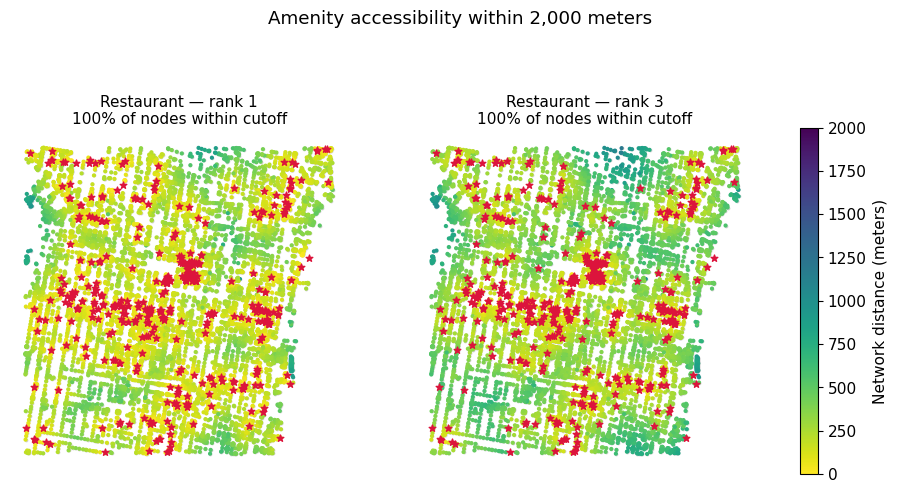

In [16]:
def plot_accessibility(category, distance=2000, ranks=(1, 3)):
    """Compare distances to selected POI ranks using a common color scale."""
    if not 0 < distance <= MAX_DISTANCE_M:
        raise ValueError(f"distance must be between 0 and {MAX_DISTANCE_M} meters.")
    if not ranks or min(ranks) < 1 or max(ranks) > NUM_POIS:
        raise ValueError(f"POI ranks must be between 1 and {NUM_POIS}.")
    access = net.nearest_pois(
        distance=distance, category=category, num_pois=max(ranks), max_distance=np.nan
    )
    mapped = walk_nodes.join(access)
    pois = poi_points.loc[poi_points.amenity == category]
    fig, axes = plt.subplots(1, len(ranks), figsize=(12, 6), squeeze=False)
    for ax, rank in zip(axes.flat, ranks):
        mapped.plot(ax=ax, color="lightgray", markersize=3)
        found = mapped.loc[mapped[rank].notna()]
        if not found.empty:
            found.plot(ax=ax, column=rank, cmap="viridis_r", markersize=4,
                       vmin=0, vmax=distance)
        pois.plot(ax=ax, color="crimson", marker="*", markersize=25, zorder=3)
        ax.set_title(f"{category.title()} — rank {rank}" + chr(10) +
                     f"{mapped[rank].notna().mean():.0%} of nodes within cutoff", fontsize=11)
        ax.set_axis_off()
    scale = plt.cm.ScalarMappable(norm=plt.Normalize(0, distance), cmap="viridis_r")
    fig.colorbar(scale, ax=list(axes.flat), shrink=0.75, label="Network distance (meters)")
    fig.suptitle(f"Amenity accessibility within {distance:,} meters")
    plt.show()
    return access

restaurant_access = plot_accessibility("restaurant")

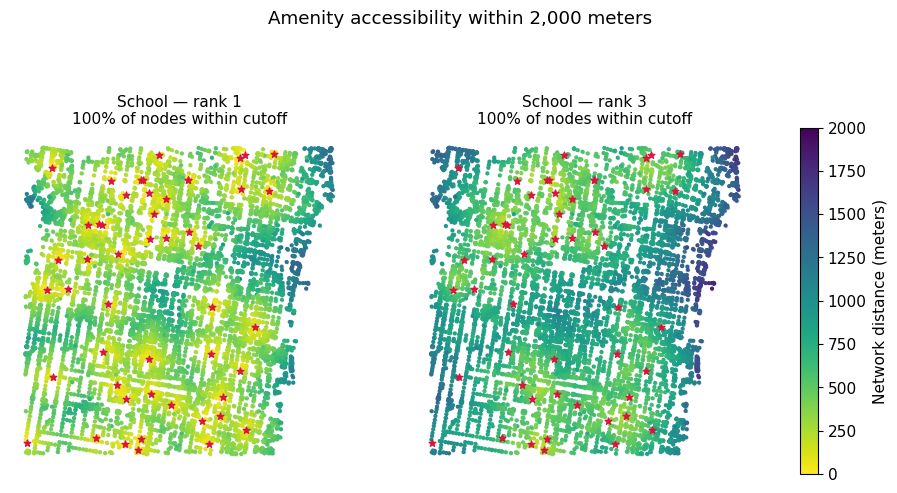

In [17]:
school_access = plot_accessibility("school")

## Interpretation and practice

**Interpret the maps carefully.** These results describe access from sampled network nodes to mapped OSM objects. They are not population-weighted access scores. Amenities beyond the downloaded boundary and routes that leave the network are omitted, producing edge effects. For a substantive study, download a surrounding buffer and report results only for an interior study area.

1. **Network type:** identify paths visible on the walking map but absent from the driving map. Why does travel mode matter?
2. **Route costs:** compare the route table. Can the shortest and fastest routes be identical? What do the estimated times leave out?
3. **Search distance:** run `plot_accessibility("restaurant", distance=1000)` and explain the additional missing results.
4. **Choice:** compare rank 1 with rank 3. Where is the gap largest, and what additional data would help explain it?
5. **New amenity:** add `"cafe"` to `AMENITIES`, rerun registration, and call `plot_accessibility("cafe")`. Check the retained count and snapping assumptions.
6. **At home:** adapt the live OSM queries to a neighborhood of your choice. Define a larger data-collection area than your reporting area, document the download date, and compare two amenity types.

### Key takeaways

- OSMnx connects OSM data, NetworkX graphs, and GeoPandas tables.
- Match coordinates and units before snapping or measuring.
- Use the same selected route edges when comparing distance and time.
- Pandana turns network routing into repeated accessibility queries.
- Missing results, boundary effects, OSM coverage, and facility duplication affect interpretation.

### References and attribution

- [OSMnx user reference](https://osmnx.readthedocs.io/en/stable/user-reference.html)
- [OSMnx example notebooks](https://github.com/gboeing/osmnx-examples)
- [Pandana network API](https://udst.github.io/pandana/network.html)
- [OpenStreetMap map features and tags](https://wiki.openstreetmap.org/wiki/Map_Features)
- Data and maps derived from © [OpenStreetMap contributors](https://www.openstreetmap.org/copyright), licensed under ODbL. Classroom data are from the lab's October 16, 2025 response cache; see `data/week8a/README.md`.